# Lab 04 — Performance measures and comparing classifiers

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

## Goal of this lab

Lab 3 ended with a question: the NordicMart tree chosen by accuracy finds 22 of 108 churners — is accuracy the right number
to choose with? Lecture 10b gave the toolbox, Lecture 11 three new classifiers. Today we put both into code, and we end by
teaching `GridSearchCV` to choose with **NordicMart's own money**.

| # | Step | Where |
|---|---|---|
| 1 | Confusion matrix, precision, recall, F1, κ, MCC — the numbers of Lecture 10b | A |
| 2 | Probabilities and thresholds | A |
| 3 | Change `scoring`, change the winner | B |
| 4 | Four classifiers with pipelines: tree, Naïve Bayes, logistic regression, kNN | C |
| 5 | One look at the test set: AUC, log loss, ROC curves | C |
| 6 | **A custom scorer with the churn costs**: cost-sensitive selection, then the threshold | D |
| ★ | The threshold tuned by scikit-learn; a different cost matrix; multi-class averages | E |

- **Part A (≈ 25 min)** — the tree of Lecture 10b, read with all the measures.
- **Part B (≈ 15 min)** — the grid of Lab 3, with six different `scoring`.
- **Part C (≈ 30 min)** — the comparison table of Lecture 11, rebuilt.
- **Part D (≈ 35 min)** — the cost experiment.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (as in Labs 1–3)

- Write code in the empty cells; write **answers in markdown cells**, not in comments.
- Raw data are never modified: every change goes into a copy with a new name.
- Every random step gets a fixed `random_state`, so that your numbers are the same as the slides'.
- The **test set is the future**. In Part A we look at it only to *reproduce* the slides of Lecture 10b: no choice is made there.
  From Part B on, every choice is made with cross-validation on the training part; the test set is opened once in C5 and once in D5.
- Before closing: **Kernel → Restart & Run All**.

## Setup

New imports: the measures of Lecture 10b (`sklearn.metrics`), the three classifiers of Lecture 11, the pieces of a pipeline,
`DummyClassifier` (the "nobody churns" baseline as a real model), `make_scorer` to build our own scoring, and
`cross_val_predict` (out-of-fold predictions).

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict,
                                     TunedThresholdClassifierCV)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, cohen_kappa_score, matthews_corrcoef, classification_report,
                             roc_auc_score, roc_curve, log_loss, make_scorer)
import sklearn

DATA_DIR = Path("../../data")
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.0.5


`TunedThresholdClassifierCV` (used only in ★ E1) needs scikit-learn 1.5 or later. If the import fails, update scikit-learn
or remove it from the import list.

# Part A — Reading a classifier with all the measures

## A1. Data, split, folds

The same preparation as Lab 3, Part C: run the cell, do not change it.

In [2]:
df = pd.read_csv(NORDICMART_FILE)
FEATURES = ["tier", "age", "days_since_last_buy", "annual_spend", "web_sessions_month", "tickets_90d"]
Xn = df[FEATURES].copy()
Xn["tier"] = Xn["tier"].map({"Basic": 0, "Silver": 1, "Gold": 2})
yn = df["churned"]

Xn_train, Xn_test, yn_train, yn_test = train_test_split(Xn, yn, test_size=0.3, stratify=yn, random_state=SEED)
cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
print(f"training: {len(yn_train)} customers, {yn_train.sum()} churners | test: {len(yn_test)} customers, {yn_test.sum()} churners")

training: 2100 customers, 252 churners | test: 900 customers, 108 churners


## A2. The confusion matrix

The running tree of Lecture 10b is `DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=0)`: the configuration
that 5-fold CV chooses when the score is AUC (we will check it in Part B).

1. Learn it on the training part; call it `tree_10b`. Predict the test set: `pred_10b`.
1. [`confusion_matrix(y_true, y_pred)`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html):
   print it. Which row is "true churn"? Which column is "predicted churn"?
1. `.ravel()` flattens it into `tn, fp, fn, tp` (in this order, for labels 0 and 1). Print the four numbers.
1. Draw it with `ConfusionMatrixDisplay.from_predictions(..., display_labels=["stay", "churn"])`.

[[764  28]
 [ 82  26]]
TN=764  FP=28  FN=82  TP=26


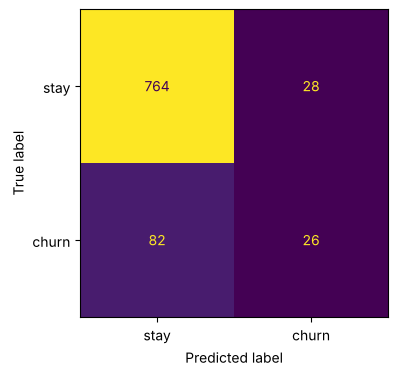

In [3]:
# your code here


**Answer.** *Write your answer here (double-click to edit).*

## A3. Measures by hand, measures by scikit-learn

1. From `tn, fp, fn, tp` only, compute accuracy, precision, recall, specificity and F1.
1. Compute the same five with scikit-learn (`accuracy_score`, `precision_score`, `recall_score`, `f1_score`; specificity is the
   recall of class 0: `recall_score(..., pos_label=0)`), plus `cohen_kappa_score` and `matthews_corrcoef`.
1. Do the same for the baseline "nobody churns": `DummyClassifier(strategy="most_frequent")`, learned on the training part.
   Its precision is $0/0$: pass `zero_division=0` to `precision_score` and `f1_score` to avoid the warning.

Put both in one DataFrame, one column per model.

In [4]:
# your code here


{'accuracy': np.float64(0.878), 'precision': np.float64(0.481), 'recall': np.float64(0.241), 'specificity': np.float64(0.965), 'F1': np.float64(0.321)}


,tree 10b,nobody churns
accuracy,0.878,0.88
precision,0.481,0.00
recall,0.241,0.00
specificity,0.965,1.00
F1,0.321,0.00
kappa,0.262,0.00
MCC,0.281,0.00


**Questions.**

1. Which measures say the tree is useful, and which say it is no better than doing nothing?
1. What does a precision of 0.48 mean for the retention team, in one sentence? And a recall of 0.24?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 

## A4. The classification report

`classification_report(y_true, y_pred, target_names=["stay", "churn"], digits=3)` prints all the per-class measures at once.
Print it for the tree.

In [5]:
# your code here


              precision    recall  f1-score   support

        stay      0.903     0.965     0.933       792
       churn      0.481     0.241     0.321       108

    accuracy                          0.878       900
   macro avg      0.692     0.603     0.627       900
weighted avg      0.852     0.878     0.859       900



**Questions.**

1. Where are the precision and recall of A3? What is the recall of the row `stay`?
1. Lecture 10b, *Averaging per-class measures*: check that the `macro avg` of F1 is the simple mean of the two F1 values,
   and the `weighted avg` the mean weighted by the `support`. Why is the weighted one so much higher?
1. Where is the *micro* average? (Hint: Lecture 10b, with one label per record.)

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

## A5. Probabilities and the threshold

`predict` uses a threshold of 0.5 on the probability of churn. `predict_proba(X)[:, 1]` gives the probability itself.

1. Compute `p_10b`, the churn probability of the test customers. How many distinct values does it have? Why?
1. Write a function `predict_at(p, t)` returning the crisp prediction `1` when `p >= t`, else `0`.
   Check that `predict_at(p_10b, 0.5)` gives exactly `pred_10b`.
1. Use `measures` of A3 with the threshold 0.15 of the slides, and compare with 0.5.
1. Draw precision, recall and F1 against the threshold, for thresholds from 0.02 to 0.75 (step 0.01), as in the slide
   *Moving the threshold: precision vs recall*.

Reminder: we are reproducing a slide on the test set. We are **not choosing** the threshold here — that is Part D, on training data.

distinct probabilities: 13 | leaves: 13
             t = 0.5  t = 0.15
accuracy       0.878     0.812
precision      0.481     0.322
recall         0.241     0.509
specificity    0.965     0.854
F1             0.321     0.394
kappa          0.262     0.290
MCC            0.281     0.301


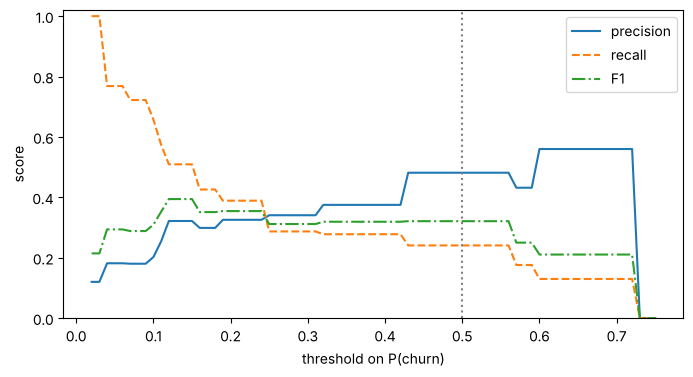

In [6]:
# your code here


**Answer.** *Write your answer here (double-click to edit).*

# Part B — Change the measure, change the winner

## B1. Six scorings on the grid of Lab 3

The grid of Lab 3: `max_depth` 2–6, `min_samples_leaf` 1, 10, 30, `criterion` gini/entropy (30 configurations).
In Lab 3 we wrote `scoring="accuracy"`. Now run the same `GridSearchCV` (estimator `DecisionTreeClassifier(random_state=0)`,
folds `cv_n`) with each of

`"accuracy"`, `"precision"`, `"recall"`, `"f1"`, `"roc_auc"`, `"neg_log_loss"`

and collect, for each, the winning configuration and its best mean CV score. (Some folds may give 0/0 precision: silence the warnings
with `warnings.catch_warnings()` as in A5.)

In [7]:
# your code here


,scoring,winner,best mean CV score
0,accuracy,entropy/d5/msl10,0.893
1,precision,gini/d3/msl1,0.639
2,recall,gini/d5/msl10,0.314
3,f1,entropy/d6/msl10,0.394
4,roc_auc,gini/d4/msl30,0.757
5,neg_log_loss,entropy/d2/msl1,-0.310


`neg_log_loss` is negative because `GridSearchCV` always **maximizes**: to minimize a loss, scikit-learn maximizes its opposite.

## B2. One search, all the measures

`scoring` also accepts a **list** of measures; then `refit` says which one chooses the final model. Run one search with
the same six measures of B1, `scoring=["accuracy", "precision", "recall", "f1", "roc_auc", "neg_log_loss"]`, and `refit="roc_auc"`.
In `cv_results_` every measure now has its own columns: `mean_test_accuracy`, `rank_test_recall`, …

For each measure, take the configuration of rank 1 and show **all six** of its mean CV scores: one row per winner, six rows.
Show the log loss with its natural sign (lower is better): change the sign of the `neg_log_loss` column.

In [8]:
# your code here


refit on roc_auc: gini/d4/msl30


,configuration,accuracy,precision,recall,f1,roc_auc,log loss
best on accuracy,entropy/d5/msl10,0.893,0.638,0.282,0.386,0.727,0.673
best on precision,gini/d3/msl1,0.888,0.639,0.231,0.322,0.723,0.378
best on recall,gini/d5/msl10,0.882,0.519,0.314,0.389,0.738,0.548
best on f1,entropy/d6/msl10,0.893,0.622,0.294,0.394,0.721,0.849
best on roc_auc,gini/d4/msl30,0.888,0.591,0.239,0.333,0.757,0.318
best on log loss,entropy/d2/msl1,0.889,0.613,0.254,0.348,0.743,0.310


**Questions.**

1. How many different winners do the six scorings produce? Which one gives the tree of Lecture 10b?
1. Read the table of B2 by columns. Is there a configuration that is best on every measure? Look in particular at the log-loss column
   (the constant guess 0.12 for everybody has log loss about 0.37).
1. The accuracy winner has precision 0.64 and recall 0.28. If the retention team said "we want to find many churners, false alarms are cheap",
   which row would you pick? And which `scoring`?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

# Part C — Four classifiers on NordicMart

## C1. The preparation of Lecture 11

Naïve Bayes, logistic regression and kNN need complete, numeric, comparable attributes. Lecture 11, *Naïve Bayes on NordicMart:
reading the results*, listed the preparation. Write a function `prepare(X)` that takes the raw columns (`Xn`) and returns a **new** DataFrame with:

| new column | from |
|---|---|
| `tier` | `tier` (already 0/1/2) |
| `age` | `age`, with 0 (default value at the till) → `NaN` |
| `recency` | `days_since_last_buy`, with 999 ("never bought") → `NaN` |
| `never_bought` | 1 if `days_since_last_buy == 999`, else 0 |
| `log_spend` | `log10(annual_spend)` |
| `sessions` | `web_sessions_month`, with `NaN` (store-only customer) → 0 |
| `store_only` | 1 if `web_sessions_month` is missing, else 0 |
| `tickets` | `tickets_90d` |

These are **fixed rules** from the EDA log: nothing is computed from the data, so they can be applied to training and test alike.
Apply it: `Xp_train = prepare(Xn_train)`, `Xp_test = prepare(Xn_test)`. How many missing values are left, and in which columns?

In [9]:
# your code here


age        237
recency     37
dtype: int64

**Answer.** *Write your answer here (double-click to edit).*

## C2. Pipelines and four searches

Lecture 11, *Standardization*: `make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), model)` is **one estimator**:
`fit` learns medians, means and standard deviations on the data it receives, then the model; `GridSearchCV` refits the whole chain in every round,
so the held-out fold never contributes to the preparation.

The hyperparameters of a step are named `<step name>__<parameter>`, where the step name is the class name in lower case
(e.g. `logisticregression__C`). Prepare a dictionary `candidates = {name: (estimator, grid, X_train)}`:

| name | estimator | grid | data |
|---|---|---|---|
| `tree` | `DecisionTreeClassifier(random_state=0)` | `max_depth` 2–6, `min_samples_leaf` 1, 10, 30 | raw: `Xn_train` |
| `naive Bayes` | pipeline + `GaussianNB()` | none: `{}` | `Xp_train` |
| `logistic regression` | pipeline + `LogisticRegression(max_iter=2000)` | `C` in 0.001, 0.01, 0.1, 1, 10, 100 | `Xp_train` |
| `kNN` | pipeline + `KNeighborsClassifier()` | `n_neighbors` in 1, 5, 15, 31, 51, 101, 201, 301, 401 | `Xp_train` |

For each: `GridSearchCV(estimator, grid, cv=cv_n, scoring="roc_auc")`, `fit`, and store the fitted search in a dictionary `searches`.
Then a table with best parameters, mean and standard deviation of the CV AUC of the winner.
(The tree keeps the raw columns, as in Lecture 10: it handles missing values and scales by itself.)

In [10]:
# your code here


,best params,CV AUC,std
model,,,
tree,"{'max_depth': 4, 'min_samples_leaf': 30}",0.757,0.030
naive Bayes,{},0.788,0.041
logistic regression,{'logisticregression__C': 0.1},0.823,0.035
kNN,{'kneighborsclassifier__n_neighbors': 401},0.819,0.032


**Questions.**

1. Which model would you choose, looking **only** at this table? Is its advantage over the second larger than the noise?
1. GaussianNB has an empty grid. What does `GridSearchCV` do then?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 

## C3. One look at the test set

The choice was made in C2. Now, **once**, measure the four refitted winners (`searches[name].best_estimator_`, or simply `searches[name]`)
on the test set — the tree on `Xn_test`, the others on `Xp_test` — and reproduce the table of Lecture 11, *Four classifiers on NordicMart*:

- test AUC and log loss (probabilities);
- precision, recall and κ at the default threshold 0.5;
- the total cost at the threshold **0.15** of the slides (fixed in Lecture 10b, not chosen here): € 10 for every false positive, € 100 for every false negative.

Add the constant model that predicts the churn rate of the training part (0.12) for everybody: AUC 0.5, and its log loss.
Store the test probabilities in a dictionary `p_test`: we will need them for the ROC curves.

In [11]:
# your code here


,CV AUC,std,test AUC,log loss,precision 0.5,recall 0.5,kappa 0.5,cost 0.15 (EUR)
model,,,,,,,,
tree,0.757,0.030,0.713,0.339,0.481,0.241,0.262,6460.0
naive Bayes,0.788,0.041,0.761,0.518,0.380,0.426,0.315,6180.0
logistic regression,0.823,0.035,0.788,0.305,0.525,0.194,0.234,5800.0
kNN,0.819,0.032,0.768,0.321,0.000,0.000,0.000,6530.0
constant 0.12,NaN,NaN,0.500,0.367,NaN,NaN,NaN,NaN


**Questions.**

1. Does the test confirm the choice made on CV? Why is each test AUC a little lower than the CV AUC?
1. Which model has the best ranking, which the best probabilities? Which is worse than the constant guess on log loss, and why?
1. kNN has κ = 0 and recall 0 at 0.5, yet the second-best test AUC. Explain.

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

## C4. ROC curves

Draw on one figure the four ROC curves on the test set (`roc_curve(yn_test, p)` returns false positive rate, true positive rate and thresholds),
with the AUC in the legend and the diagonal of the random classifier.

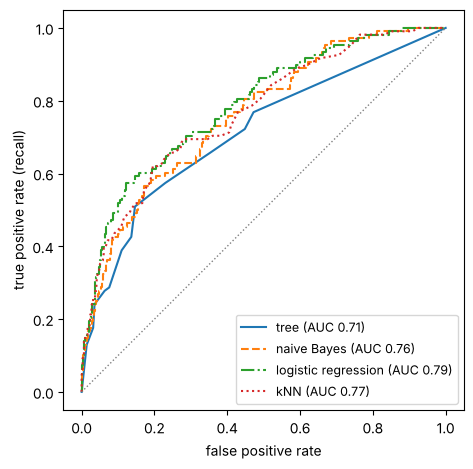

In [12]:
# your code here


**Question.** The tree's curve is made of a few straight segments, the others are much finer. Why? Do the curves cross?

**Answer.** *Write your answer here (double-click to edit).*

# Part D — A custom scorer with the churn costs

Lecture 10b, *NordicMart: a cost matrix*: a flagged customer receives an offer that costs **€ 10**; a churner who is not flagged is lost,
with **€ 100** of margin. Assumption: the offer keeps the churners it reaches.

| | predicted stay | predicted churn |
|---|---|---|
| **true stay** | 0 | € 10 (FP) |
| **true churn** | € 100 (FN) | 0 (TP) |

Every measure of Part B was a **proxy** for this table. Now we give the table itself to `GridSearchCV`.

## D1. The cost function

1. Write `churn_cost(y_true, y_pred)` returning the total cost in euros. Use `confusion_matrix(..., labels=[0, 1])`, so that it works
   even when a fold contains predictions of one class only.
1. The CV folds have 420 customers, the test set 900: to compare them, write also `cost_per_customer(y_true, y_pred)`, the average cost
   in euros per customer.
1. Check on the slide: the tree of Lecture 10b at threshold 0.5 on the test set costs € 8 480; "nobody gets the offer" € 10 800;
   "everybody gets it" € 7 920. Print also the three costs per customer.

In [13]:
# your code here


tree 10b, t = 0.5  EUR  8,480    9.42 per customer
nobody             EUR 10,800   12.00 per customer
everybody          EUR  7,920    8.80 per customer


## D2. `make_scorer`: choosing the tree by cost

[`make_scorer`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.make_scorer.html) turns a function
`f(y_true, y_pred)` into a `scoring` object. `GridSearchCV` maximizes, and a cost must be minimized: say so with
`greater_is_better=False` (scikit-learn will report the cost with a minus sign).

1. `cost_scorer = make_scorer(cost_per_customer, greater_is_better=False)`.
1. Run the tree grid of Part B (`param_grid`, 30 configurations) with `scoring=cost_scorer`. Winner, and its CV cost per customer
   (remember the sign)? Compare with the two trivial strategies on the training part: 100 · (churn rate) per customer for "nobody",
   10 · (1 − churn rate) for "everybody".
1. **Cost-sensitive learning** (Lecture 10b): add `class_weight` to the grid, with values `None`, `"balanced"` and `{0: 1, 1: 10}`
   (a churner counts as ten customers in the impurity). Run it again. Winner, cost, and the best cost reached by each value of `class_weight`.

In [14]:
# your code here


winner gini/d5/msl10: EUR 8.59 per customer | nobody 12.00 | everybody 8.80


with class_weight: entropy/d5/msl30, class_weight={0: 1, 1: 10}: EUR 5.96 per customer


class_weight
None             8.590
balanced         6.319
{0: 1, 1: 10}    5.957
Name: best CV cost per customer, dtype: float64

**Questions.**

1. Without `class_weight`, does choosing by cost help much? Why can no tree, at threshold 0.5, get close to the cost of the slide at 0.15?
1. With `class_weight={0: 1, 1: 10}` the cost falls a lot. What does the weight do to the leaves of the tree? Relate the factor 10 to the cost matrix.

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 

## D3. A scorer that looks at the probabilities

`class_weight` works for the tree, but the other route of Lecture 10b is to keep the model and **move the threshold**. `make_scorer`
receives crisp predictions, made at 0.5. We need a scorer that reads the probabilities and applies our threshold.

A scorer can also be a plain function **`scorer(estimator, X, y)`** returning a number to maximize. Write

```python
def cost_scorer_at_t(estimator, X, y):
    ...   # probabilities of `estimator` on X, prediction at THRESHOLD, minus the cost per customer
```

with `THRESHOLD = COST_FP / (COST_FP + COST_FN)` (= 0.09: the cost-optimal threshold of Lecture 10b *if the probabilities are correct*).
It is fixed by the cost matrix, before looking at any data.

Then run the four searches of C2 again, with the same grids, but `scoring={"cost": cost_scorer_at_t, "auc": "roc_auc"}` and `refit="cost"`
(two measures, the cost chooses). Store them in `cost_searches`. Table: winner, CV cost per customer ± std, CV AUC of the same configuration.

In [15]:
# your code here


threshold 0.091


,best params,CV cost/customer,std,CV AUC
model,,,,
tree,"{'max_depth': 4, 'min_samples_leaf': 30}",6.086,0.540,0.757
naive Bayes,{},5.962,0.864,0.788
logistic regression,{'logisticregression__C': 10},5.329,0.793,0.823
kNN,{'kneighborsclassifier__n_neighbors': 401},5.467,0.741,0.819


**Questions.**

1. Rank the four models by CV cost. Is it the same ranking as by AUC in C2? Did any winning hyperparameter change?
1. The tree without weights at 0.09 (€ 6.09) costs about the same as the weighted tree of D2 at 0.5 (€ 5.96). Coincidence?
1. Logistic regression and kNN are again close. How many euros per customer separate them, compared with the standard deviation?

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

## D4. The threshold, chosen on training data

0.09 is optimal only if the probabilities are exactly right. Lecture 10b: *choose the threshold on training or validation data, not on the test set*.
We need probabilities for the training customers that were **not** produced by a model that saw them:
[`cross_val_predict`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html)
with `method="predict_proba"` returns, for each training customer, the probability given by the model of the round in which that customer was held out
(**out-of-fold** probabilities).

1. Take the cost winner of D3 for logistic regression, `final_lr = cost_searches["logistic regression"].best_estimator_`.
1. Compute its out-of-fold probabilities on the training part (`cv=cv_n`): `p_oof`.
1. For thresholds from 0.02 to 0.60 (step 0.01) compute the cost per customer on the training part; plot it, with horizontal lines for
   "nobody" and "everybody". Which threshold is best (`best_t`)? Compare with 0.09 and 0.5.

best threshold 0.13: EUR 5.20 | at 0.09: 5.33 | at 0.5: 9.56


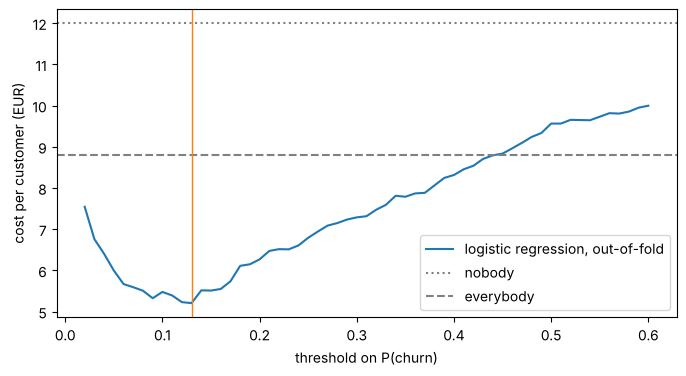

In [16]:
# your code here


**Question.** Is the best threshold close to the theoretical 0.09? How sharp is the minimum: how much would we lose with any threshold between 0.07 and 0.17?

**Answer.** *Write your answer here (double-click to edit).*

## D5. One look at the test set

The decision is now complete and written down **before** opening the test set: logistic regression with the C chosen by CV cost (D3), threshold `best_t` chosen
on out-of-fold probabilities (D4). `final_lr` was already refitted on all 2100 training customers by `GridSearchCV`.

1. Cost on the test set (total and per customer), its confusion matrix, precision and recall.
1. Compare with: "nobody", "everybody", the tree of Lecture 10b at 0.5 (€ 8 480), and logistic regression at the slide's 0.15 (C3).

In [17]:
# your code here


[[610 182]
 [ 38  70]]
precision 0.278 | recall 0.648


,total cost (EUR),per customer
nobody gets the offer,10800.0,12.000
everybody gets the offer,7920.0,8.800
"tree 10b, t = 0.5",8480.0,9.422
"logistic regression (C3), t = 0.15",5800.0,6.444
"final: LR, cost-chosen, t = 0.13",5620.0,6.244


**Questions.**

1. How many churners does the final model find, and how many offers does it send? Compare with the tree of Lab 3 (22 churners found, 14 false alarms).
1. The test cost per customer is higher than the CV estimate of D4. Is this worrying?
1. Lecture 10b, wrap-up: "costs decide: measure, threshold, operating point". Summarize in two sentences what the cost matrix changed in this lab.

**Answers.** *Write your answers here (double-click to edit).*

1. 
1. 
1. 

# Part E — Optional exercises ★

## E1. scikit-learn tunes the threshold ★

D4 is common enough that scikit-learn (≥ 1.5) has a meta-estimator for it:
[`TunedThresholdClassifierCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html).
It wraps a classifier, computes out-of-fold probabilities, chooses the threshold that maximizes `scoring`, and refits.

Wrap `final_lr` with `scoring=cost_scorer` (the crisp scorer of D2: the wrapper applies each candidate threshold before calling it) and `cv=cv_n`;
`fit` it on the training part. Print `best_threshold_`, `-best_score_` and the cost on the test set. Compare with D4–D5.

In [18]:
# your code here


threshold 0.121 | CV cost per customer 5.23 | test cost EUR 5,580


**Answer.** *Write your answer here (double-click to edit).*

## E2. A more honest cost matrix ★

The cost matrix of the slides is generous: the offer is free when it reaches a churner, and it always keeps them. Suppose instead that
the offer costs € 10 **to everybody who receives it**, and keeps only **40%** of the churners it reaches. Then a true positive costs
10 + 0.6 · 100 = € 70.

1. Write `churn_cost_2(y_true, y_pred)` with the new matrix (TP € 70, FP € 10, FN € 100, TN 0).
1. Derive the theoretical threshold: flag a customer with churn probability $p$ when the expected cost of flagging, $70p + 10(1-p)$,
   is lower than the expected cost of not flagging, $100p$.
1. With `p_oof` of D4: cost curve per customer, best threshold, and the costs of "nobody" and "everybody". Is the campaign still worth it?

theoretical threshold: 0.25
best 0.24: EUR 10.84 per customer | nobody 12.00 | everybody 17.20


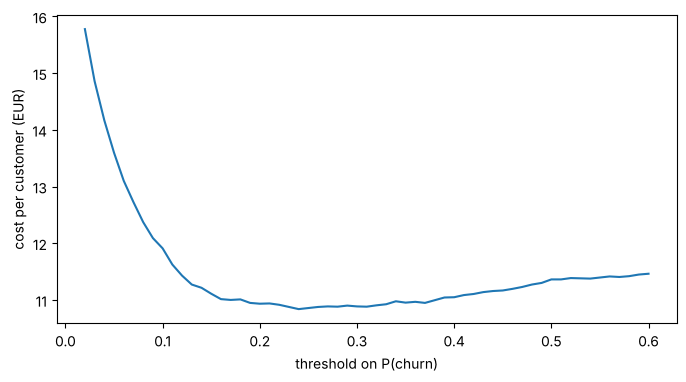

In [19]:
# your code here


**Answer.** *Write your answer here (double-click to edit).*

## E3. Three classes: the averages on Iris ★

Rebuild the Iris data of Lab 3, Part A (50-50 split, `random_state=10`, flowers 113 and 125 altered), learn
`DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=10)` on the altered training set and print the confusion matrix and the
classification report on the test set (`target_names=iris.target_names`). Which class has the lowest precision, which the lowest recall?
Why are macro and weighted averages so close here, unlike NordicMart?

In [20]:
# your code here


[[23  0  0]
 [ 0 22  5]
 [ 0  1 24]]
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        23
  versicolor      0.957     0.815     0.880        27
   virginica      0.828     0.960     0.889        25

    accuracy                          0.920        75
   macro avg      0.928     0.925     0.923        75
weighted avg      0.927     0.920     0.920        75



**Answer.** *Write your answer here (double-click to edit).*

## Experiment log

Complete the log (double-click to edit). Costs on the test set are in euros, for the 900 test customers.

| Model | Chosen by | Threshold | CV | Test AUC | Test cost |
|---|---|---|---|---|---|
| *nobody gets the offer* | *—* | *—* | *—* | *0.5* | *€ 10 800* |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the test set was used only in A (to reproduce the slides), C3–C4 and D5 (and E1, ★).

In [21]:
# quick self-check
assert len(Xn_test) == 900 and yn_test.sum() == 108
assert (tn, fp, fn, tp) == (764, 28, 82, 26)
assert churn_cost(yn_test, pred_10b) == 8480
assert searches["tree"].best_params_ == {"max_depth": 4, "min_samples_leaf": 30}
print("ok")

ok
